# **Proyecto de marketing bancario**
## Objetivo: de predecir si un cliente contratará un servicio

## Importamos todas las librerías que vamos a necesitar:

In [1]:
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

**Fuente de datos:** [Bank Marketing (UCI Machine Learning Repository)](https://archive.ics.uci.edu/dataset/222/bank+marketing),
fichero `bank-full.csv` (dentro de `bank.zip`). Licencia CC BY 4.0.

Referencia: S. Moro, P. Cortez y P. Rita (2014). *A Data-Driven Approach to Predict the Success of Bank Telemarketing*. Decision Support Systems.

**En caso de querer ejecutar vd. mismo el notebook, basta con agregar el fichero 'bank-full.csv' junto al notebook**

## Cargar los datos:
- Indicamos que los datos vienen separados por ; (no por , como suele ser habitual)

In [2]:
df = pd.read_csv("bank-full.csv", sep=";")

## Visualizacion en consola de una muestra de los datos:

In [3]:
#print("dataframe_head:\n", df.head())
#print("\n")
df.head()


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


## Filas y Columnas de dataframe
## Mostramos tb los tipos de datos

In [4]:
print("numero de filas: ", df.shape[0]) # tb vale len(df)
print("numero de columnas: ", df.shape[1])
print("\n")

print("df_types:\n", df.dtypes)
print("\n")

numero de filas:  45211
numero de columnas:  17


df_types:
 age          int64
job            str
marital        str
education      str
default        str
balance      int64
housing        str
loan           str
contact        str
day          int64
month          str
duration     int64
campaign     int64
pdays        int64
previous     int64
poutcome       str
y              str
dtype: object




## Mostramos las columnas (features)
( incluída la columna objetivo 'y' )

In [5]:
print("df_columns:\n ", df.columns)
print("\n")

df_columns:
  Index(['age', 'job', 'marital', 'education', 'default', 'balance', 'housing',
       'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'y'],
      dtype='str')




## Mostramos info del dataframe:

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 5.9 MB


## Valores generales de dataframe (describe):

In [7]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


## Checkeamos si hay datos corruptos (vacíos / NaN)...

In [8]:
print("Algun valor NaN o vacio? ", df.isnull().values.any())
print("Suma de valores NaN o vacio? ", df.isnull().values.sum())
print("\n")

Algun valor NaN o vacio?  False
Suma de valores NaN o vacio?  0




## Asignamos algunas constates:

In [9]:
RANDOM_STATE = 22 # Fijada semilla aleatoria

## Separación de variables:
- **X** Features
- **y** Target

**Excluimos `duration`** (duración de la llamada): solo se conoce cuando la llamada ya ha terminado, así que no está disponible al decidir a quién llamar. Usarla sería *data leakage* e inflaría las métricas, como advierte la documentación del dataset.

In [10]:
X = df.drop(columns=["y", "duration"])
y = df["y"]
y.head()

0    no
1    no
2    no
3    no
4    no
Name: y, dtype: str

## Separar columnas:
- **numeric_features** columnas de tipo numérico
- **categorical_features** columnas de tipo categórico

In [11]:
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns
categorical_features = X.select_dtypes(include=["object", "string"]).columns

print("\nNumeric_features:\n", numeric_features.to_list())
print("\nCat_features:\n", categorical_features.to_list())


Numeric_features:
 ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']

Cat_features:
 ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


## Separación de los datos en: **Train / Test**

In [12]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

## Preprocesamiento **(numéricas)**

In [13]:
numeric_transformer = Pipeline([
    ("scaler", MinMaxScaler())
])

## Preprocesamiento **(categóricas)**

In [14]:
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("one_hot_encoder", OneHotEncoder(handle_unknown="ignore"))
])

## Transformación **(numéricas y categóricas)**

In [15]:
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

## Creamos el model **Decision Tree**, asignándo estos hiperparámetros:
- **param 1**: Aplicamos el parámetro clave: class_weight="balanced" para manejar el desbalanceo
- **param 2**: random_state=22 (para que el aleatorio sea siempre igual en cada ejecucion)

In [16]:
dt_model = Pipeline([
    ("prep", preprocessor),
    ("classifier", DecisionTreeClassifier(class_weight="balanced", random_state=22))
])

## Creamos el model **Random Forest**, asignando estos hiperparámetros:
- **param 1**: n_estimators entre 100-200 (suficientes para un buen resultado)
- **param 2** :  entre 0.2-0.5
- **param 3**: Aplicamos balanced para manejar el desbalanceo
- **param 4**: Random_state 22 para que NO cambie el aleatorio en cada ejecucion

In [17]:
rf_model = Pipeline([
    ("prep", preprocessor),
    ("classifier", RandomForestClassifier(n_estimators=150, min_samples_split=0.3, class_weight="balanced", random_state=22))
])

## **Creamos una función**
## Para entrenar los diferentes modelos
entrenar_modelo()

In [18]:
def entrenar_modelo(name, model):
  """
  Función para entrenar los diferentes modelos:
  - Recibe como parametros: una descripción del modelo y el propio modelo
  - Devuelve: una variable con las predicciones 'y_pred'
  """
  # Entrenar modelo:
  model.fit(X_train, y_train)

  # Predicciones:
  y_pred = model.predict(X_test)

  # Metricas (clasification_report):
  print("=" * 55)
  print(f"--- MÉTRICAS {name} ---")
  print("=" * 55)
  print(classification_report(y_test, y_pred))

  # Metricas (confusion-matrix):
  print(f"--- CONFUSION MATRIX ({name}) ---")
  print(confusion_matrix(y_test, y_pred))
  print("\n")

  return y_pred



## Invocamos la función creada anteriormente:
(*Una vez por cada modelo que queramos entrenar*)

In [19]:
entrenar_modelo("DECISION TREE", dt_model)
entrenar_modelo("RANDOM FOREST", rf_model)

--- MÉTRICAS DECISION TREE ---
              precision    recall  f1-score   support

          no       0.91      0.90      0.90      7971
         yes       0.30      0.31      0.30      1072

    accuracy                           0.83      9043
   macro avg       0.60      0.60      0.60      9043
weighted avg       0.83      0.83      0.83      9043

--- CONFUSION MATRIX (DECISION TREE) ---
[[7195  776]
 [ 743  329]]




--- MÉTRICAS RANDOM FOREST ---
              precision    recall  f1-score   support

          no       0.94      0.58      0.72      7971
         yes       0.19      0.72      0.30      1072

    accuracy                           0.60      9043
   macro avg       0.56      0.65      0.51      9043
weighted avg       0.85      0.60      0.67      9043

--- CONFUSION MATRIX (RANDOM FOREST) ---
[[4652 3319]
 [ 299  773]]




array(['no', 'no', 'no', ..., 'no', 'yes', 'no'],
      shape=(9043,), dtype=object)

# **Conclusión Decision-Tree:**

Aún con el parámetro class_weight=balanced, al modelo le cuesta distinguir patrones de contratación (f1-score del 30 %).

Solo tiene **buen resultado** en patrones de **no contratación**, al tener muchos más ejemplos de los que aprender (f1-score del 90 %).

En la matriz de confusión encuentra a 329 clientes que contratan y deja "escapar" a 743.

# **Conclusión Random-Forest:**

El Decision Tree tiene mejor Accuracy (83 % frente a 60 %) y ambos empatan en F1-Score (0,30), pero para una campaña de marketing el **modelo más útil es el Random Forest**: su Recall del 72 % capta a la mayoría de los clientes interesados.

En la matriz de confusión capta a 773 clientes y deja "escapar" a 299. El coste son 3.319 llamadas a clientes que no contratarán: su precisión es del 19 %, frente al 11,9 % de contrataciones en el conjunto de test si se llama al azar.

Como devuelve una probabilidad, también permite priorizar: **llamando solo al 30 % de clientes con mayor probabilidad se capta el 62 % de las contrataciones**, aproximadamente el doble que llamando al azar.

# **Visualización de resultados**
Configuramos un estilo común para las gráficas:

In [20]:
import numpy as np

AZUL, GRIS, TINTA, TINTA_2 = "#2a78d6", "#9a9992", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 130, "font.size": 11, "text.color": TINTA,
    "axes.edgecolor": "#d8d7d2", "axes.labelcolor": TINTA_2,
    "xtick.color": TINTA_2, "ytick.color": TINTA_2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlelocation": "left", "axes.titleweight": "bold", "axes.titlesize": 14,
})

## **Curva de ganancia**
Si el banco ordena a los clientes por probabilidad de contratar (Random Forest), ¿qué parte de las contrataciones consigue llamando solo a una parte de ellos?

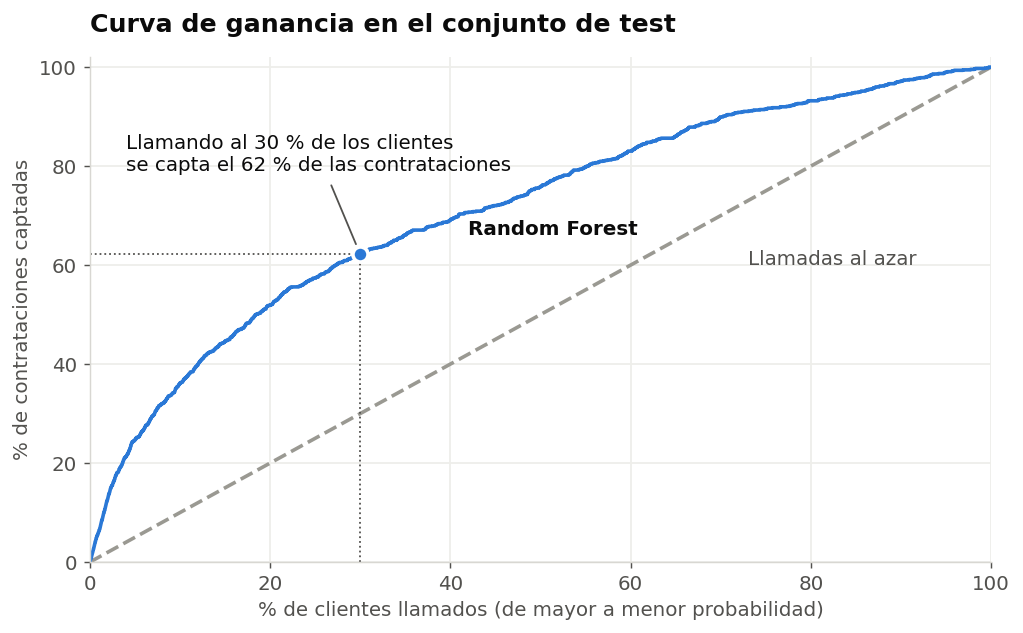

Top 30 %: 62.2 % de las contrataciones


In [21]:
proba = rf_model.predict_proba(X_test)[:, list(rf_model.classes_).index("yes")]
orden = np.argsort(-proba, kind="stable")
aciertos = (y_test.to_numpy()[orden] == "yes").cumsum()
pct_clientes = np.arange(1, len(orden) + 1) / len(orden) * 100
pct_contrataciones = aciertos / aciertos[-1] * 100

corte = 30
valor_corte = np.interp(corte, pct_clientes, pct_contrataciones)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot([0, 100], [0, 100], color=GRIS, lw=2, ls="--")
ax.plot(pct_clientes, pct_contrataciones, color=AZUL, lw=2)
ax.plot([corte, corte], [0, valor_corte], color=TINTA_2, lw=1, ls=":")
ax.plot([0, corte], [valor_corte, valor_corte], color=TINTA_2, lw=1, ls=":")
ax.scatter([corte], [valor_corte], s=70, color=AZUL, edgecolor="white", linewidth=2, zorder=3)
ax.annotate(f"Llamando al {corte} % de los clientes\nse capta el {valor_corte:.0f} % de las contrataciones",
            (corte, valor_corte), xytext=(4, 79), color=TINTA,
            arrowprops=dict(arrowstyle="-", color=TINTA_2, lw=1, shrinkA=4, shrinkB=6))
ax.text(42, 66, "Random Forest", color=TINTA, weight="bold")
ax.text(73, 60, "Llamadas al azar", color=TINTA_2)
ax.set(xlim=(0, 100), ylim=(0, 102), xlabel="% de clientes llamados (de mayor a menor probabilidad)",
       ylabel="% de contrataciones captadas")
ax.grid(color="#eeeeea", lw=1); ax.set_axisbelow(True)
ax.set_title("Curva de ganancia en el conjunto de test", pad=14)
plt.tight_layout(); plt.show()
print(f"Top {corte} %: {valor_corte:.1f} % de las contrataciones")

## **Matrices de confusión**
El color indica el porcentaje dentro de cada clase real.

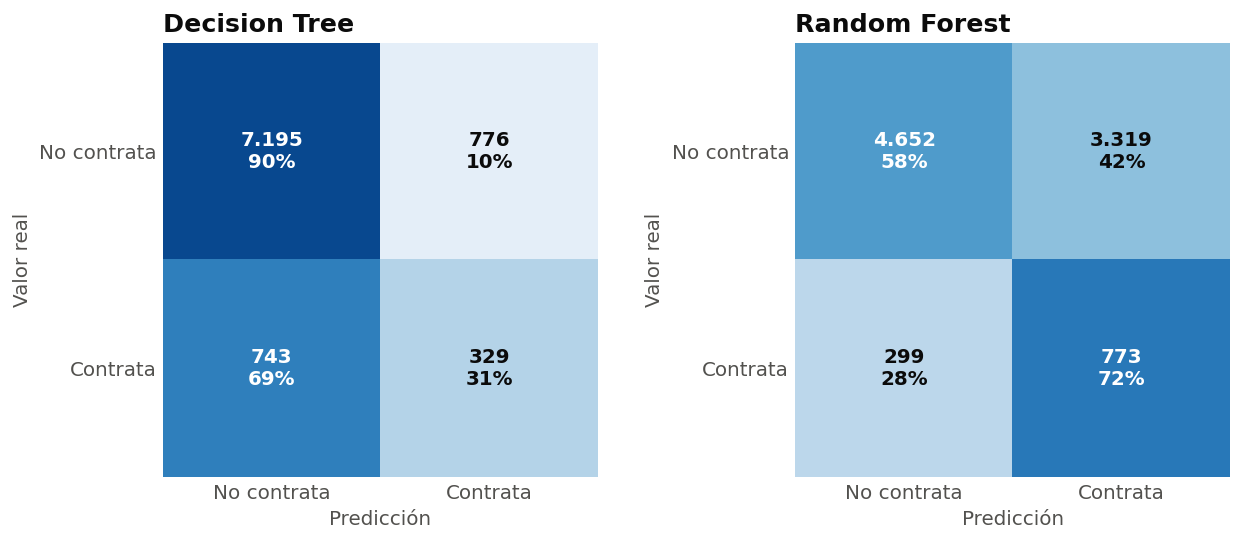

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.3))
etiquetas = ["No contrata", "Contrata"]
for ax, (nombre, modelo) in zip(axes, [("Decision Tree", dt_model), ("Random Forest", rf_model)]):
    cm = confusion_matrix(y_test, modelo.predict(X_test), labels=["no", "yes"])
    pct = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(pct, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}".replace(",", ".") + f"\n{pct[i, j]:.0%}", ha="center", va="center",
                    color="white" if pct[i, j] > .55 else TINTA, weight="bold")
    ax.set_xticks([0, 1], etiquetas); ax.set_yticks([0, 1], etiquetas)
    ax.set(xlabel="Predicción", ylabel="Valor real"); ax.set_title(nombre)
    ax.tick_params(length=0)
    for s in ax.spines.values(): s.set_visible(False)
plt.tight_layout(); plt.show()

## **Variables más influyentes (Random Forest)**
Sumamos la importancia de las columnas *one-hot* de cada variable original.

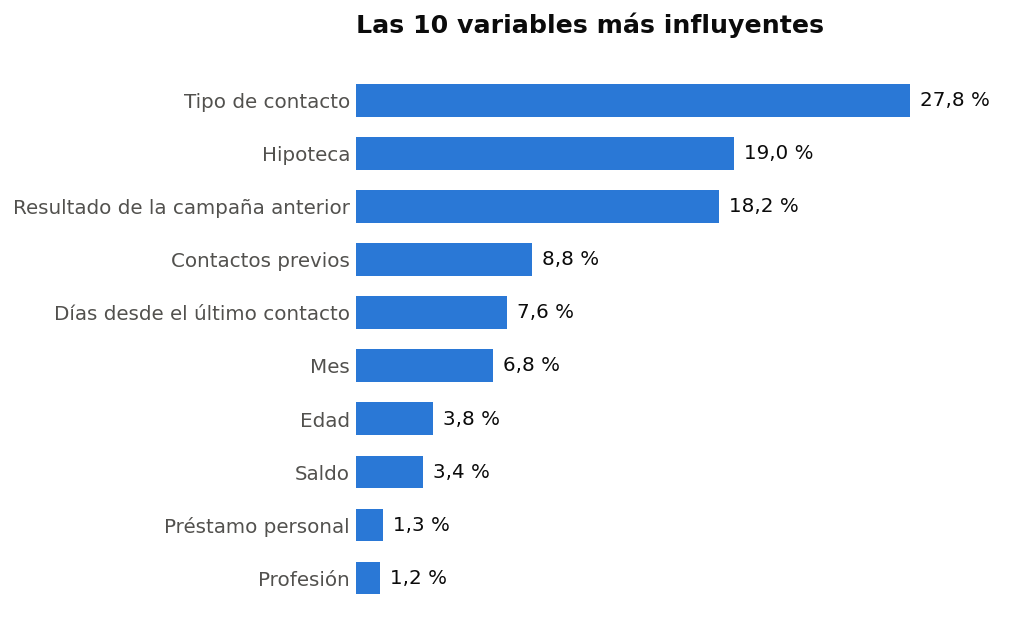

contact      27.8
housing      19.0
poutcome     18.2
previous      8.8
pdays         7.6
month         6.8
age           3.8
balance       3.4
loan          1.3
job           1.2
marital       0.9
campaign      0.8
education     0.3
day           0.2
default       0.0


In [23]:
NOMBRES = {"age": "Edad", "job": "Profesión", "marital": "Estado civil", "education": "Educación",
           "default": "Impago de crédito", "balance": "Saldo", "housing": "Hipoteca", "loan": "Préstamo personal",
           "contact": "Tipo de contacto", "day": "Día del mes", "month": "Mes", "campaign": "Contactos en esta campaña",
           "pdays": "Días desde el último contacto", "previous": "Contactos previos",
           "poutcome": "Resultado de la campaña anterior"}
columnas = rf_model.named_steps["prep"].get_feature_names_out()
importancias = rf_model.named_steps["classifier"].feature_importances_

def variable_original(col):
    tipo, resto = col.split("__", 1)
    return resto if tipo == "num" else next(v for v in categorical_features if resto.startswith(v + "_"))

imp = pd.Series(importancias, index=[variable_original(c) for c in columnas]).groupby(level=0).sum()
top = imp.sort_values(ascending=False).head(10).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh([NOMBRES[v] for v in top.index], top * 100, color=AZUL, height=.62)
for i, v in enumerate(top * 100):
    ax.text(v + .5, i, f"{v:.1f} %".replace(".", ","), va="center", color=TINTA)
ax.set_xlim(0, top.max() * 118); ax.xaxis.set_visible(False)
ax.spines["bottom"].set_visible(False); ax.spines["left"].set_visible(False); ax.tick_params(length=0)
ax.set_title("Las 10 variables más influyentes", pad=14)
plt.tight_layout(); plt.show()
print((imp.sort_values(ascending=False) * 100).round(1).to_string())